# Part 5 — Open-ended image retrieval challenge

Retrieval system for the category **motorbike**: given a query (an image or a
text), score every image of a fixed corpus and return a ranked list. **No
classifier is trained** — every method only encodes images and compares
vectors.

All features come from the caches of Parts 1–4 (`data/encodings/<feature>/`).
Run from `code/`. BoVW with K = 256 and 1024 (vocabulary-size question) is
built with the README commands:

```bash
python -m src.train   -e bovw -k 256 -c 0 --splits-file ../data/splits/splits.json --img-dir ../data/images --output-dir ../data/encoders
python -m src.extract -e ../data/encoders/bovw_K256_C0.npz --splits-file ../data/splits/splits.json --img-dir ../data/images --output-dir ../data/encodings/ --cache-dir ""
# same for -k 1024
```

**Protocol**

| Item | Choice | Why |
|---|---|---|
| Target category | motorbike | Focus class of Part 1; 125 test images; hard negatives (bicycles, people, cars). |
| Test corpus | all 2474 **test** images (125 relevant) | Fixed, same for every method; never seen when building vocabularies/PCA. |
| Validation corpus | all 495 **val** images (24 relevant) | Used to choose normalisation, K, PCA dim, ResNet layer and CLIP prompt. |
| Ground truth | relevant ⇔ `motorbike` ∈ labels of the image (`splits.json`) | Objective labels; multi-label images (motorbike + person) count as relevant. |
| Query pool | the 96 **train** images with a motorbike | Disjoint from both corpora → no exact duplicates; near-duplicates checked below. |
| Query sets | *diverse* (12, k-means medoids), *typical* (12 closest to the mean), *all* (96) | Answers the query-diversity question; *all* gives the most stable mAP. |
| Vocabularies / PCA | fitted on **train** only | No information from the corpora leaks into the representation. |
| Metrics | AP per query → mAP ± std; P@5/10/20; R@5/10/20 | Stage C list; R@K is possible because the number of relevant images is known. |

In [1]:
import platform, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, sklearn
from src import retrieval as R
from src.evaluate import load_clip, encode_text, extraction_costs

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
R.RESULTS.mkdir(parents=True, exist_ok=True); R.FIGS.mkdir(parents=True, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Python {platform.python_version()} | torch {torch.__version__} | scikit-learn {sklearn.__version__} | numpy {np.__version__}")
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")

def save(fig, name):
    fig.savefig(R.FIGS / f"{name}.png", dpi=130, bbox_inches="tight")

Python 3.11.17 | torch 2.14.0+cu130 | scikit-learn 1.9.1 | numpy 2.4.6
Device: NVIDIA GeForce RTX 5060 Ti


## Stage A — Corpus, ground truth and queries

### A1. Corpora and ground truth

In [2]:
summary = pd.DataFrame({s: R.corpus_summary(R.load_raw("dinov2_vits14", s)) for s in ("val", "test")})
summary.to_csv(R.RESULTS / "stageA_corpus_composition.csv")
summary

,val,test
images,495,2474
relevant,24,125
"relevant, single label",7,37
"relevant, multi-label",17,88
irrelevant with aeroplane,22,126
irrelevant with car,72,320
irrelevant with horse,28,148
irrelevant with person,189,898
irrelevant with background,204,1077


The irrelevant images include many **hard negatives**: people (often next to
bicycles or vehicles), cars and street scenes. The class is rare (≈ 5 % of the
test corpus), so a random ranking has AP ≈ 0.05.

### A2. Query pool and near-duplicate check

Queries come from the train split, so they are never *exact* copies of corpus
images. Near-duplicates (the same photo re-encoded or slightly cropped) are
searched with DINOv2 cosine similarity > 0.95; the closest pairs are shown even
if they are below the threshold, for visual inspection.

In [3]:
pool = R.query_pool()
dups = pd.concat([R.near_duplicates(pool, s).assign(corpus_subset=s) for s in ("val", "test")])
print(f"Query pool: {len(pool)} motorbike images of the train split")
print(f"Near-duplicate pairs (cos > 0.95): {len(dups)}")
closest = pd.concat([R.near_duplicates(pool, s, thr=0.0).head(3).assign(corpus_subset=s) for s in ("val", "test")])
closest

Query pool: 96 motorbike images of the train split
Near-duplicate pairs (cos > 0.95): 0


,query,corpus,cosine,corpus_subset
18384,005156,009776,0.945,val
7589,001941,005951,0.905,val
29889,009756,005951,0.895,val
38946,001941,009781,0.920,test
151527,009756,009781,0.913,test
150439,009756,002367,0.892,test


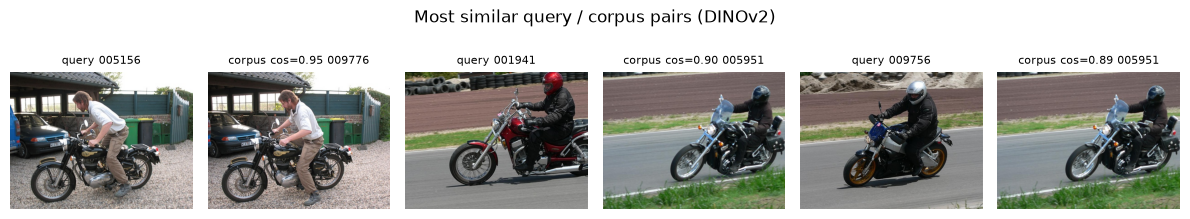

In [4]:
pairs = closest.head(3)
fig = R.show_queries(np.ravel(pairs[["query", "corpus"]].values),
                     [f"{k} {n}" for q, c, s in zip(pairs["query"], pairs["corpus"], pairs["cosine"])
                      for k, n in (("query", q), (f"corpus cos={s:.2f}", c))],
                     ncols=6, title="Most similar query / corpus pairs (DINOv2)")
save(fig, "stageA_closest_pairs")

overlap diverse/typical: 2


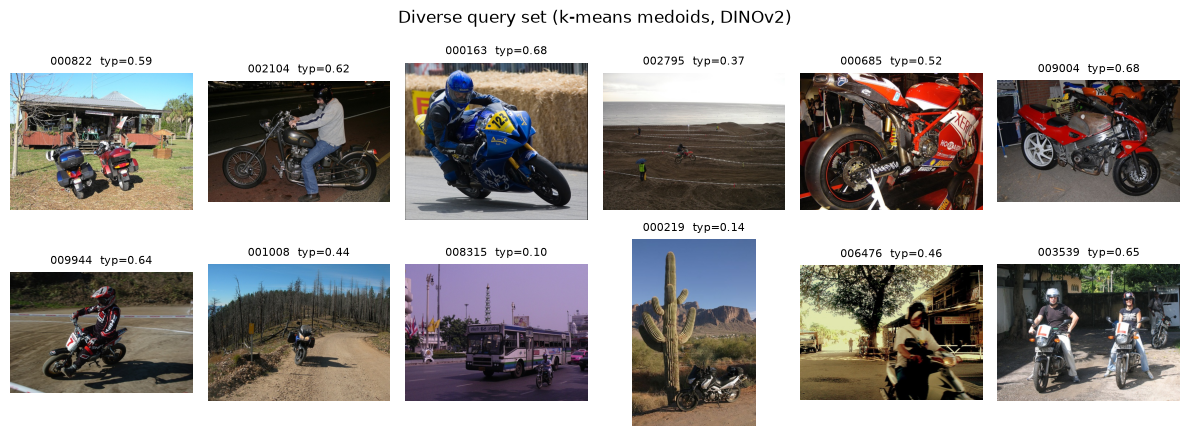

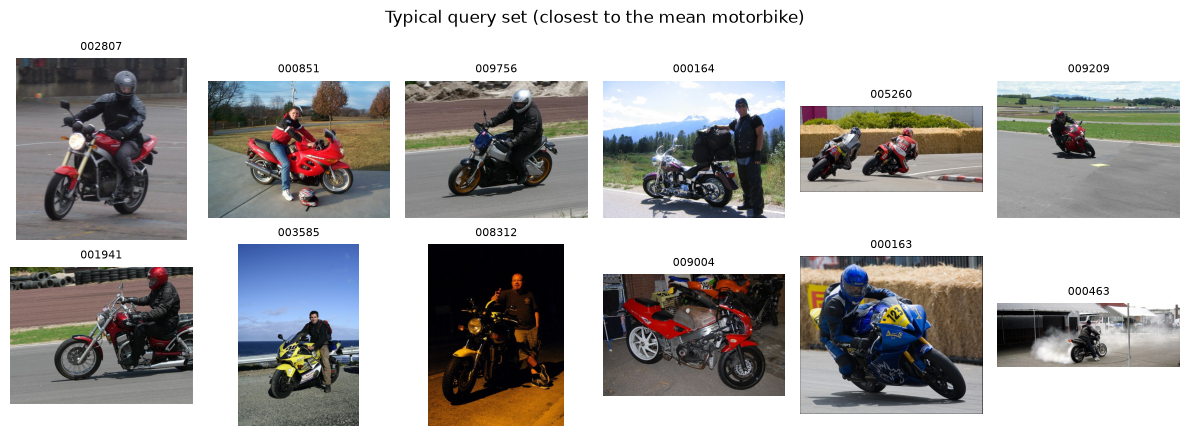

In [5]:
pool = np.array([q for q in pool if q not in set(dups["query"])])   # drop near-duplicate queries
diverse = R.diverse_queries(pool, n=12)
typical = R.typical_queries(pool, n=12)
QUERY_SETS = {"diverse (12)": diverse, "typical (12)": typical, f"all ({len(pool)})": pool}
pd.Series(diverse, name="query").to_csv(R.RESULTS / "stageA_queries_diverse.csv", index=False)
pd.Series(typical, name="query").to_csv(R.RESULTS / "stageA_queries_typical.csv", index=False)
print("overlap diverse/typical:", len(set(diverse) & set(typical)))
typ = R.typicality(diverse, pool)
fig = R.show_queries(diverse, [f"{q}  typ={t:.2f}" for q, t in zip(diverse, typ)], title="Diverse query set (k-means medoids, DINOv2)")
save(fig, "stageA_queries_diverse")
fig = R.show_queries(typical, list(typical), title="Typical query set (closest to the mean motorbike)")
save(fig, "stageA_queries_typical")

`typ` = cosine of the query to the mean motorbike embedding (1 = very
prototypical). The *diverse* set is chosen automatically (12 k-means clusters
of the DINOv2 embeddings, the medoid of each), which is reproducible and covers
different views, scales and contexts. Using DINOv2 to select the queries could
favour DINOv2, so the main comparison uses **all** 96 queries.

## Stage B — Retrieval strategies

Every method = (feature, normalisation, optional PCA, similarity). Variants:

| Family | Variants | Notes |
|---|---|---|
| **1. BoVW** (dense SIFT, 2×2 tiling, K = 256/512/1024) | raw + Euclidean · L1 + Euclidean · L2 + cosine · Hellinger (√L1) + cosine · L1 + histogram intersection | Hellinger = square root of the L1 histogram, then L2 (Part 1, Stage F). |
| BoVW + PCA | Hellinger + PCA 128 / 256 / 1024 (K = 1024) and 128 / 256 (K = 512) | PCA fitted on train; K=1024+PCA1024 has the same dim as K=256 (Part 3 design). |
| **2. VLAD** (K = 32, d = 80) | L2 · power (signed √) + L2 · power + PCA 128 / 256 | Power normalisation reduces the weight of bursty visual words. |
| **2. Fisher vector** (K = 32, d = 80) | L2 · power + L2 · power + PCA 128 / 256 | |
| **3. ResNet-18** (GAP of layer2/3/4) | L2 + cosine | Layer chosen on val. |
| **3. DINOv2 ViT-S/14** | CLS · mean of patch tokens (optional patch-level item) | L2 + cosine. |
| CLIP ViT-B/32 image encoder | L2 + cosine | Image→image, for reference. |
| **4. CLIP text → image** | 8 prompts of increasing detail (+ a *bicycle* control) | Prompt chosen on val. |

### B1. Define the variants

In [6]:
M = R.Method
methods = []
bovw_ks = [k for k in (256, 512, 1024) if R.has_feature(f"bovw_K{k}_C0")]
print("BoVW vocabularies available:", bovw_ks)
for k in bovw_ks:
    f = f"bovw_K{k}_C0"
    methods += [M(f"BoVW K{k} raw+euclid",  "BoVW", f, "raw", "euclid"),
                M(f"BoVW K{k} L1+euclid",   "BoVW", f, "l1", "euclid"),
                M(f"BoVW K{k} L2+cos",      "BoVW", f, "l2"),
                M(f"BoVW K{k} Hellinger+cos", "BoVW", f, "hellinger"),
                M(f"BoVW K{k} L1+HIK",      "BoVW", f, "l1", "hik")]
for k, dims in ((512, (128, 256)), (1024, (128, 256, 1024))):
    if k in bovw_ks:
        methods += [M(f"BoVW K{k} Hellinger+PCA{d}", "BoVW", f"bovw_K{k}_C0", "hellinger", pca=d) for d in dims]
for fam, f in (("VLAD", "vlad_K32_C80"), ("FV", "fv_K32_C80")):
    methods += [M(f"{fam} L2+cos", fam, f, "l2"), M(f"{fam} power+cos", fam, f, "power")]
    methods += [M(f"{fam} power+PCA{d}", fam, f, "power", pca=d) for d in (128, 256)]
methods += [M(f"ResNet-18 {l}", "ResNet-18", f"resnet18_{l}") for l in ("layer2", "layer3", "layer4")]
methods += [M("DINOv2 CLS", "DINOv2", "dinov2_vits14"),
            M("DINOv2 patch-mean", "DINOv2", "dinov2_vits14_patchmean"),
            M("CLIP image", "CLIP image", "clip_vit_b_32")]
t0 = time.time()
for m in methods:
    m.fit()                                   # PCA on train only
print(f"{len(methods)} variants, PCA fitted in {time.time() - t0:.1f}s")

BoVW vocabularies available: [256, 512, 1024]
34 variants, PCA fitted in 8.8s


### B2. Choose each family's variant on the **validation** corpus

Queries: all train motorbikes; corpus: val (24 relevant out of 495). The test
corpus is not used for any choice.

In [7]:
val_tab, val_ap, _ = R.run(methods, pool, "val")
best = R.pick_best(val_tab)
val_tab.to_csv(R.RESULTS / "stageB_val_all_variants.csv")
print("Chosen on val:"); print(best.to_string())
val_tab.sort_values("mAP", ascending=False)[["family", "dim", "mAP", "AP std", "P@5", "P@10", "P@20"]]

Chosen on val:
family
DINOv2                      DINOv2 CLS
ResNet-18             ResNet-18 layer4
CLIP image                  CLIP image
BoVW          BoVW K1024 Hellinger+cos
FV                     FV power+PCA256
VLAD                    VLAD power+cos


,family,dim,mAP,AP std,P@5,P@10,P@20
method,,,,,,,
DINOv2 CLS,DINOv2,384,0.664,0.267,0.815,0.749,0.655
DINOv2 patch-mean,DINOv2,384,0.568,0.262,0.729,0.679,0.572
ResNet-18 layer4,ResNet-18,512,0.562,0.245,0.708,0.657,0.553
CLIP image,CLIP image,512,0.472,0.231,0.713,0.611,0.473
ResNet-18 layer3,ResNet-18,256,0.229,0.148,0.394,0.308,0.242
ResNet-18 layer2,ResNet-18,128,0.171,0.106,0.273,0.225,0.185
BoVW K1024 Hellinger+cos,BoVW,4096,0.126,0.063,0.179,0.157,0.131
BoVW K512 Hellinger+cos,BoVW,2048,0.125,0.063,0.181,0.155,0.132
BoVW K256 Hellinger+cos,BoVW,1024,0.121,0.059,0.177,0.149,0.123


### B3. CLIP text → image

Each prompt is one query. The prompt is chosen on val; the test column is only
reported (to discuss prompt sensitivity, not to pick).

In [8]:
clip_model = load_clip(device)
rows, text_S = [], {}
for subset in ("val", "test"):
    rel = R.relevance(R.load_raw("clip_vit_b_32", subset))
    t0 = time.perf_counter()
    S = R.text_scores(clip_model, R.TEXT_QUERIES, subset, encode_text)
    text_S[subset] = S
    for p, s in zip(R.TEXT_QUERIES, S):
        rows.append({"prompt": p, "subset": subset, **R.ranking_metrics(s, rel)})
text_tab = pd.DataFrame(rows).pivot(index="prompt", columns="subset", values=["AP", "P@10", "P@20"]).loc[R.TEXT_QUERIES]
text_tab.to_csv(R.RESULTS / "stageB_clip_text_prompts.csv")
candidates = [p for p in R.TEXT_QUERIES if "bicycle" not in p]          # the control is not a candidate
best_prompt = text_tab.loc[candidates, ("AP", "val")].idxmax()
print("Chosen prompt (val AP):", best_prompt)
text_tab

Chosen prompt (val AP): a photo of a motorbike, a motorcycle, a scooter or a dirt bike.


AP        P@10       \
subset                                               test    val test  val   
prompt                                                                       
motorbike                                           0.881  0.925  1.0  1.0   
a photo of a motorbike.                             0.840  0.879  1.0  0.9   
a photo of a motorcycle.                            0.848  0.843  1.0  0.9   
a photo of a person riding a motorbike.             0.853  0.864  1.0  1.0   
a photo of a motorbike parked on the street.        0.751  0.730  1.0  0.8   
a close-up photo of a motorbike with two wheels...  0.765  0.795  0.9  0.9   
a photo of a motorbike, a motorcycle, a scooter...  0.888  0.942  1.0  0.9   
a photo of a bicycle.                               0.256  0.174  0.0  0.0   

                                                    P@20        
subset                                              test   val  
prompt                                                          
motorbike                                           1.00  0.90  
a photo of a motorbike.                             0.90  0.85  
a photo of a motorcycle.                            1.00  0.85  
a photo of a person riding a motorbike.             1.00  0.75  
a photo of a motorbike parked on the street.        1.00  0.75  
a close-up photo of a motorbike with two wheels...  0.90  0.75  
a photo of a motorbike, a motorcycle, a scooter...  0.95  0.95  
a photo of a bicycle.                               0.00  0.15

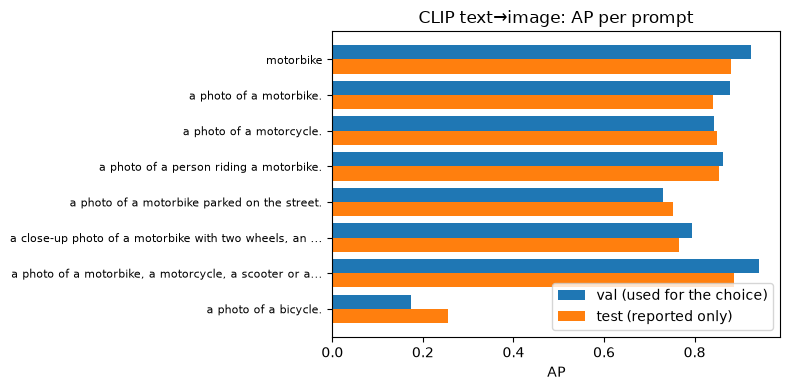

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(R.TEXT_QUERIES))
ax.barh(y - .2, text_tab[("AP", "val")], .4, label="val (used for the choice)")
ax.barh(y + .2, text_tab[("AP", "test")], .4, label="test (reported only)")
ax.set_yticks(y, [p if len(p) < 55 else p[:52] + "..." for p in R.TEXT_QUERIES], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("AP"); ax.legend(); ax.set_title("CLIP text→image: AP per prompt")
fig.tight_layout(); save(fig, "stageB_clip_prompts")

## Stage C — Evaluation on the test corpus

### C1. All variants (analysis) and the val-chosen ones (final)

In [10]:
test_tab, test_ap, test_S = R.run(methods, pool, "test")
test_tab["chosen on val"] = test_tab.index.isin(best.values)
test_tab.to_csv(R.RESULTS / "stageC_test_all_variants.csv")
test_ap.to_csv(R.RESULTS / "stageC_test_ap_per_query.csv")
test_tab[["family", "dim", "mAP", "AP std", "P@5", "P@10", "P@20", "R@20", "chosen on val"]]

,family,dim,mAP,AP std,P@5,P@10,P@20,R@20,chosen on val
method,,,,,,,,,
BoVW K256 raw+euclid,BoVW,1024,0.083,0.025,0.144,0.121,0.119,0.019,False
BoVW K256 L1+euclid,BoVW,1024,0.089,0.029,0.194,0.153,0.137,0.022,False
BoVW K256 L2+cos,BoVW,1024,0.068,0.029,0.123,0.102,0.096,0.015,False
BoVW K256 Hellinger+cos,BoVW,1024,0.105,0.042,0.248,0.214,0.190,0.030,False
BoVW K256 L1+HIK,BoVW,1024,0.103,0.041,0.240,0.210,0.189,0.030,False
BoVW K512 raw+euclid,BoVW,2048,0.081,0.023,0.123,0.106,0.099,0.016,False
BoVW K512 L1+euclid,BoVW,2048,0.088,0.029,0.196,0.148,0.134,0.022,False
BoVW K512 L2+cos,BoVW,2048,0.063,0.027,0.092,0.091,0.086,0.014,False
BoVW K512 Hellinger+cos,BoVW,2048,0.108,0.044,0.252,0.218,0.196,0.031,False


### C2. Vocabulary size and PCA (BoVW)

,dim,mAP,P@10,P@20
method,,,,
BoVW K256 Hellinger+cos,1024,0.105,0.214,0.190
BoVW K512 Hellinger+cos,2048,0.108,0.218,0.196
BoVW K1024 Hellinger+cos,4096,0.110,0.234,0.205
BoVW K512 Hellinger+PCA128,128,0.092,0.166,0.153
BoVW K512 Hellinger+PCA256,256,0.092,0.172,0.151
BoVW K1024 Hellinger+PCA128,128,0.093,0.165,0.157
BoVW K1024 Hellinger+PCA256,256,0.093,0.167,0.155
BoVW K1024 Hellinger+PCA1024,1024,0.093,0.179,0.154


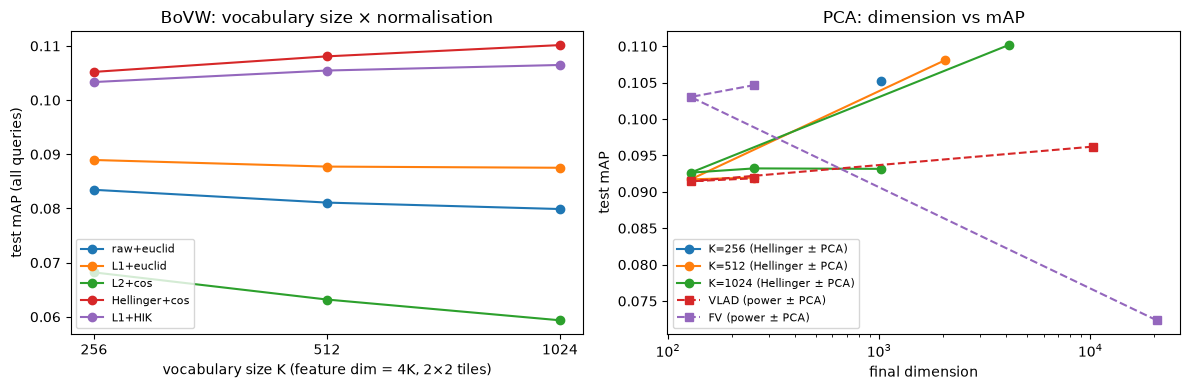

In [11]:
bovw = test_tab[test_tab.family == "BoVW"].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for prep in ("raw+euclid", "L1+euclid", "L2+cos", "Hellinger+cos", "L1+HIK"):
    pts = [(k, test_tab.loc[f"BoVW K{k} {prep}", "mAP"]) for k in bovw_ks]
    axes[0].plot(*zip(*pts), marker="o", label=prep)
axes[0].set_xscale("log", base=2); axes[0].set_xticks(bovw_ks, bovw_ks)
axes[0].set_xlabel("vocabulary size K (feature dim = 4K, 2×2 tiles)"); axes[0].set_ylabel("test mAP (all queries)")
axes[0].set_title("BoVW: vocabulary size × normalisation"); axes[0].legend(fontsize=8)
for k in bovw_ks:
    sel = bovw[bovw.index.str.startswith(f"BoVW K{k} Hellinger")]
    axes[1].plot(sel["dim"], sel["mAP"], marker="o", label=f"K={k} (Hellinger ± PCA)")
for fam in ("VLAD", "FV"):
    sel = test_tab[(test_tab.family == fam) & test_tab.index.str.contains("power")]
    axes[1].plot(sel["dim"], sel["mAP"], marker="s", ls="--", label=f"{fam} (power ± PCA)")
axes[1].set_xscale("log"); axes[1].set_xlabel("final dimension"); axes[1].set_ylabel("test mAP")
axes[1].set_title("PCA: dimension vs mAP"); axes[1].legend(fontsize=8)
fig.tight_layout(); save(fig, "stageC_vocabulary_pca")
cols = ["dim", "mAP", "P@10", "P@20"]
bovw[bovw.index.str.contains("Hellinger")][cols]

### C3. Main comparison (val-chosen variant of each family) with costs

* **Extraction** (ms/image): deep features from `results/deep_extraction.csv`
  (GPU, batch 64, decoding + preprocessing + forward); handcrafted features are
  timed here on 20 test images (CPU: dense SIFT + encoding, no cache).
* **Storage**: float32, `dim × 4` bytes per image and for the whole test corpus.
* **Query time**: scoring + sorting the 2474 encoded corpus images for one
  query (CPU, numpy), best of 3 runs.

In [12]:
sample = R.load_raw("dinov2_vits14", "test").names[:20]
deep = extraction_costs()["ms_per_img_total"]
def extraction_ms(feature):
    if feature in deep.index:
        return deep[feature]
    return R.handcrafted_extraction_ms(f"{feature}.npz", sample)

by_name = {m.name: m for m in methods}
rows = []
for fam, name in best.items():
    m = by_name[name]
    rows.append({"family": fam, "method": name, **test_tab.loc[name, ["dim", "mAP", "AP std", "P@5", "P@10", "P@20", "R@5", "R@10", "R@20"]],
                 "extraction ms/img": extraction_ms(m.feature),
                 "storage B/img": 4 * m.dim, "corpus MB": 4 * m.dim * 2474 / 1e6,
                 "query ms": R.query_time_ms(m, pool[:20], "test")})
# CLIP text -> image (one query per prompt; the chosen prompt is reported)
rel_test = R.relevance(R.load_raw("clip_vit_b_32", "test"))
t_txt = R.ranking_metrics(text_S["test"][R.TEXT_QUERIES.index(best_prompt)], rel_test)
t_enc = []
for _ in range(5):                                   # first call = warm-up, keep the best
    t0 = time.perf_counter(); encode_text(clip_model, [best_prompt]); t_enc.append(1000 * (time.perf_counter() - t0))
t_enc = min(t_enc)
rows.append({"family": "CLIP text", "method": f'CLIP text: "{best_prompt}"', "dim": 512, "mAP": t_txt["AP"], "AP std": np.nan,
             **{k: t_txt[k] for k in ("P@5", "P@10", "P@20", "R@5", "R@10", "R@20")},
             "extraction ms/img": deep["clip_vit_b_32"], "storage B/img": 2048, "corpus MB": 2048 * 2474 / 1e6,
             "query ms": t_enc + R.query_time_ms(R.Method("clip", "CLIP image", "clip_vit_b_32"), pool[:20], "test")})
main = pd.DataFrame(rows).set_index("family").sort_values("mAP", ascending=False)
main.to_csv(R.RESULTS / "stageC_main_comparison.csv")
main.to_markdown(R.RESULTS / "stageC_main_comparison.md", floatfmt=".3f")
print("CLIP text query time includes encoding the prompt on", device)
main

CLIP text query time includes encoding the prompt on cuda


,method,dim,mAP,AP std,P@5,P@10,P@20,R@5,R@10,R@20,extraction ms/img,storage B/img,corpus MB,query ms
family,,,,,,,,,,,,,,
CLIP text,"CLIP text: ""a photo of a motorbike, a motorcyc...",512.0,0.888,NaN,1.000,1.000,0.950,0.040,0.080,0.152,3.826,2048,5.067,6.451
DINOv2,DINOv2 CLS,384.0,0.645,0.249,0.856,0.844,0.831,0.034,0.068,0.133,4.538,1536,3.800,0.140
ResNet-18,ResNet-18 layer4,512.0,0.548,0.229,0.771,0.752,0.730,0.031,0.060,0.117,3.923,2048,5.067,0.164
CLIP image,CLIP image,512.0,0.464,0.210,0.796,0.769,0.738,0.032,0.061,0.118,3.826,2048,5.067,0.141
BoVW,BoVW K1024 Hellinger+cos,4096.0,0.110,0.047,0.265,0.234,0.205,0.011,0.019,0.033,206.956,16384,40.534,0.607
FV,FV power+PCA256,256.0,0.105,0.048,0.246,0.208,0.188,0.010,0.017,0.030,183.439,1024,2.533,0.181
VLAD,VLAD power+cos,10240.0,0.096,0.039,0.200,0.176,0.157,0.008,0.014,0.025,157.006,40960,101.335,2.058


For CLIP text there is a single query per prompt, so its mAP is the AP of the
chosen prompt (no std). The image methods average over 96 queries.

### C4. Precision–recall curves (mean over queries)

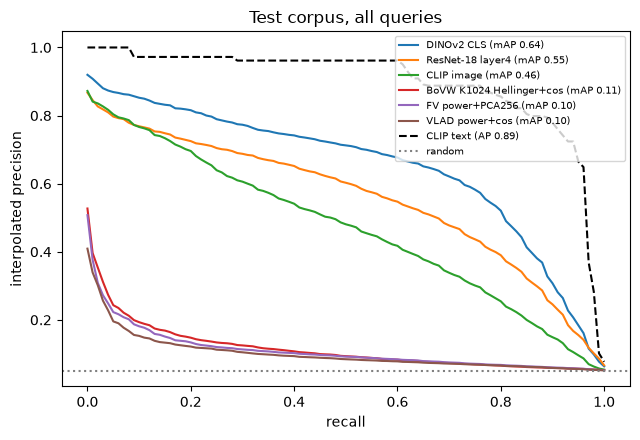

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for fam, name in best.items():
    lv, p = R.pr_curve(test_S[name], rel_test)
    ax.plot(lv, p, label=f"{name} (mAP {test_tab.loc[name, 'mAP']:.2f})")
lv, p = R.pr_curve(text_S["test"][R.TEXT_QUERIES.index(best_prompt)], rel_test)
ax.plot(lv, p, "k--", label=f"CLIP text (AP {t_txt['AP']:.2f})")
ax.axhline(rel_test.mean(), color="grey", ls=":", label="random")
ax.set_xlabel("recall"); ax.set_ylabel("interpolated precision"); ax.set_title("Test corpus, all queries")
ax.legend(fontsize=7); fig.tight_layout(); save(fig, "stageC_pr_curves")

### C5. Sensitivity to the query set

mAP of every chosen method with the three query sets. *mean query* = one
single query made of the average embedding of the 12 diverse queries (a simple
way of combining several examples).

In [14]:
rows = {}
for fam, name in best.items():
    m = by_name[name]
    r = {}
    for qs_name, qs in QUERY_SETS.items():
        r[qs_name] = test_ap.loc[qs, name].mean() if qs_name.startswith("all") else \
            R.evaluate(R.score_queries(m, qs, "test"), rel_test, qs)["AP"].mean()
    Q = m.transform(R.embed(m.feature, "train", diverse))
    q_mean = Q.mean(0, keepdims=True)
    if m.sim == "cos":
        q_mean = R.l2norm(q_mean)
    C = m.transform(R.load_raw(m.feature, "test").X)
    r["mean query (diverse)"] = R.ranking_metrics(R.similarity(q_mean, C, m.sim)[0], rel_test)["AP"]
    rows[name] = r
qsets = pd.DataFrame(rows).T
qsets.to_csv(R.RESULTS / "stageC_query_sets.csv")
qsets

,diverse (12),typical (12),all (96),mean query (diverse)
DINOv2 CLS,0.587,0.841,0.645,0.938
ResNet-18 layer4,0.501,0.741,0.548,0.824
CLIP image,0.430,0.646,0.464,0.791
BoVW K1024 Hellinger+cos,0.115,0.134,0.110,0.154
FV power+PCA256,0.115,0.137,0.105,0.231
VLAD power+cos,0.102,0.127,0.096,0.176


Spearman correlation typicality vs AP:
DINOv2 CLS                  0.79
ResNet-18 layer4            0.79
CLIP image                  0.75
BoVW K1024 Hellinger+cos    0.41
FV power+PCA256             0.48
VLAD power+cos              0.41


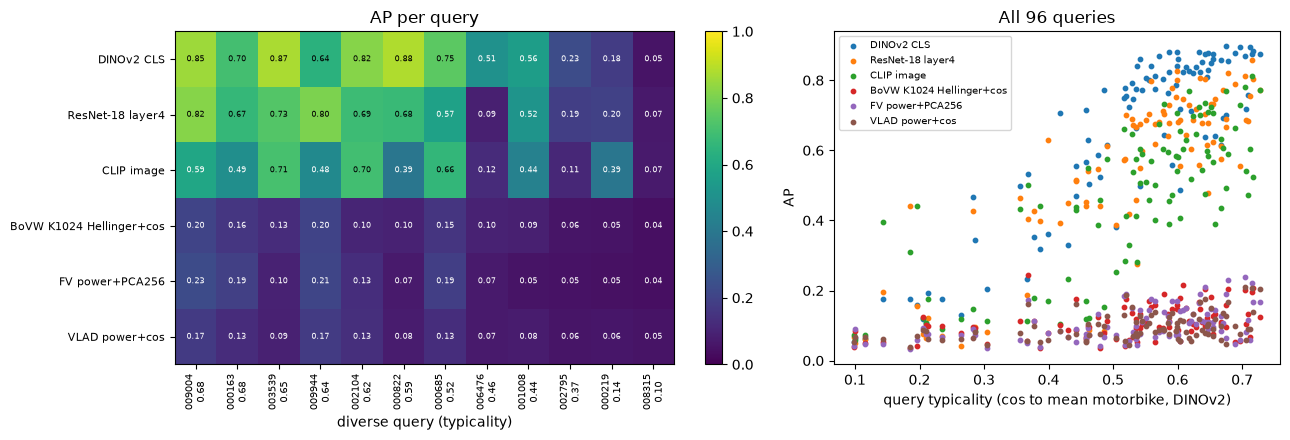

In [15]:
names = list(best.values)
ap_div = pd.DataFrame({n: R.evaluate(R.score_queries(by_name[n], diverse, "test"), rel_test, diverse)["AP"] for n in names})
ap_div["typicality"] = R.typicality(diverse, pool)
ap_div = ap_div.sort_values("typicality", ascending=False)
ap_div.to_csv(R.RESULTS / "stageC_ap_diverse_queries.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
im = axes[0].imshow(ap_div[names].T.values, cmap="viridis", aspect="auto", vmin=0, vmax=1)
axes[0].set_yticks(range(len(names)), names, fontsize=8)
axes[0].set_xticks(range(len(ap_div)), [f"{q}\n{t:.2f}" for q, t in zip(ap_div.index, ap_div.typicality)], fontsize=7, rotation=90)
axes[0].set_xlabel("diverse query (typicality)"); axes[0].set_title("AP per query")
for i, n in enumerate(names):
    for j, v in enumerate(ap_div[n]):
        axes[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="w" if v < .6 else "k")
fig.colorbar(im, ax=axes[0])
typ_all = R.typicality(pool, pool)
for n in names:
    axes[1].scatter(typ_all, test_ap.loc[pool, n], s=10, label=n)
axes[1].set_xlabel("query typicality (cos to mean motorbike, DINOv2)"); axes[1].set_ylabel("AP")
axes[1].set_title("All 96 queries"); axes[1].legend(fontsize=7)
fig.tight_layout(); save(fig, "stageC_query_sensitivity")
print("Spearman correlation typicality vs AP:")
print(pd.Series({n: pd.Series(typ_all).corr(pd.Series(test_ap.loc[pool, n].values), method="spearman") for n in names}).round(2).to_string())

### C6. Representative results: successes and failures

For the best method, the queries with the highest, median and lowest AP;
the same queries are then shown for BoVW. Green = motorbike, red = not a
motorbike; the label under each image is its ground-truth label set.

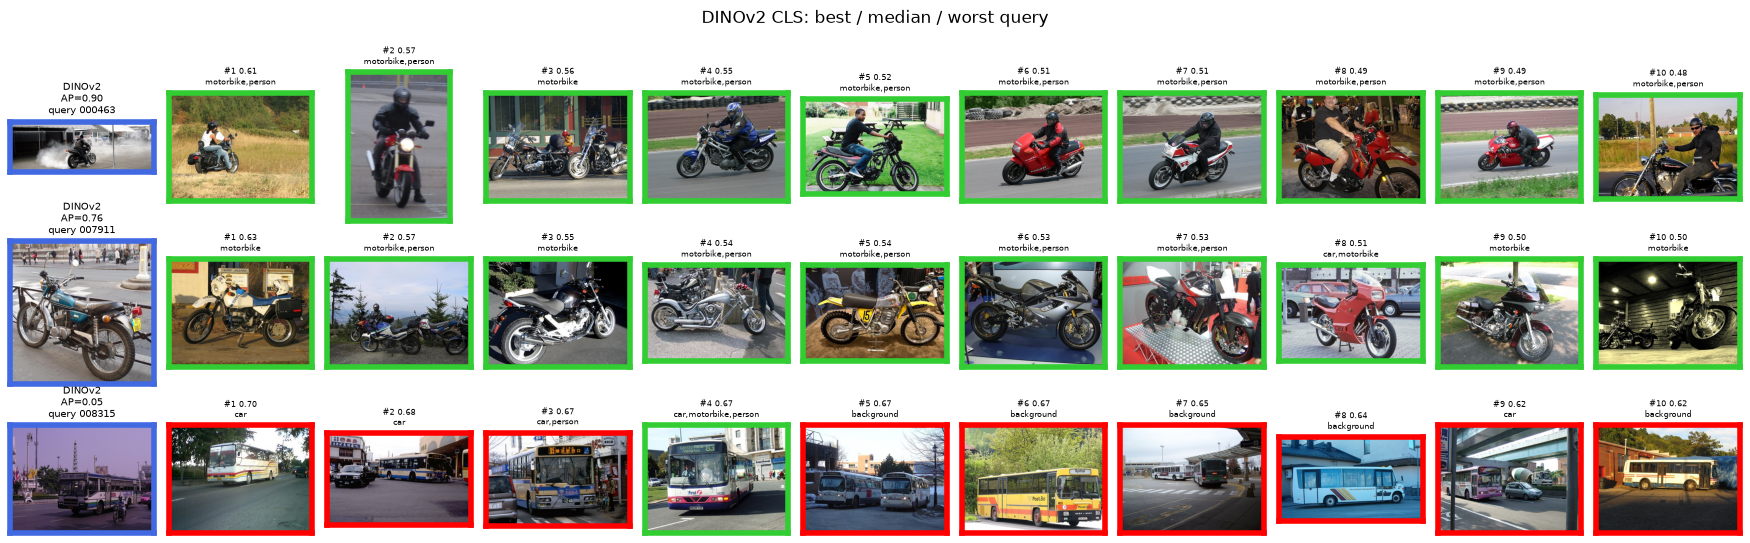

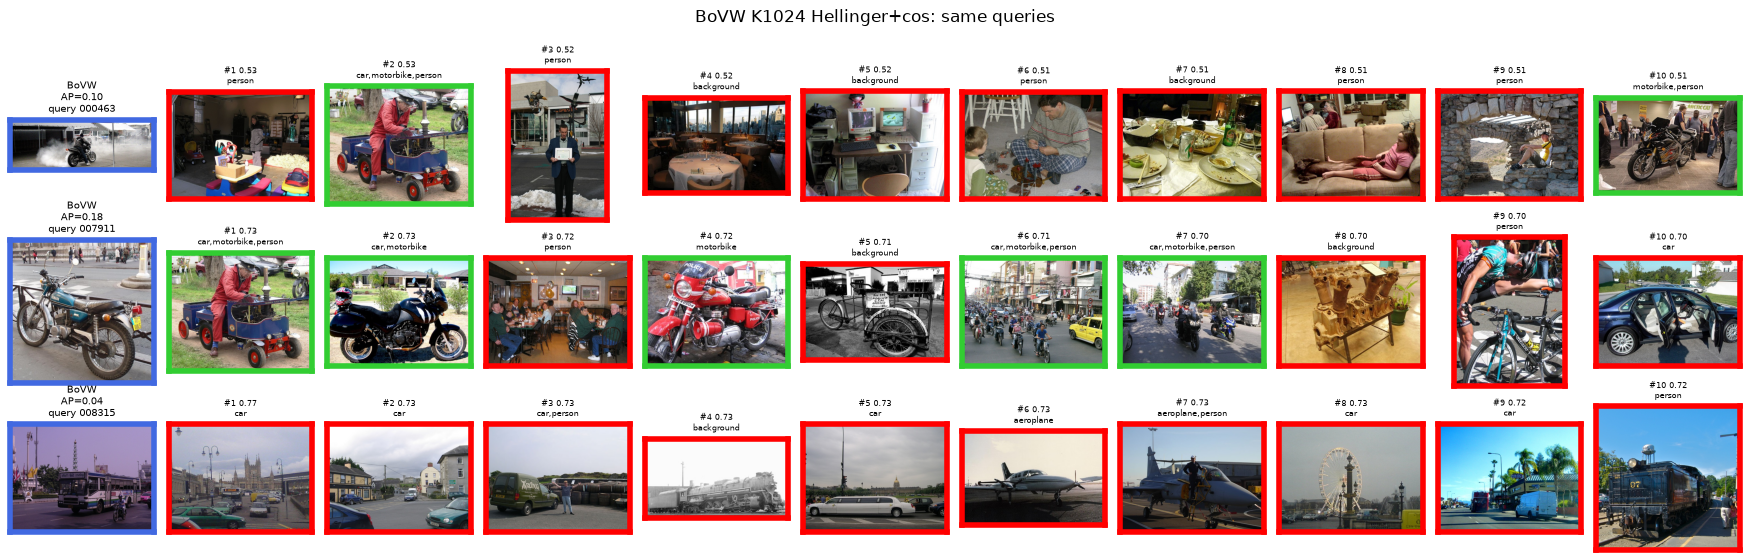

In [16]:
best_method = main.index[0] if main.index[0] != "CLIP text" else main.index[1]
best_name = best[best_method]
aps = test_ap.loc[pool, best_name].sort_values()
picked = [aps.index[-1], aps.index[len(aps) // 2], aps.index[0]]
rows = [(f"{best_method}\nAP={aps[q]:.2f}", q, test_S[best_name][list(pool).index(q)]) for q in picked]
fig = R.show_results(rows, "test", title=f"{best_name}: best / median / worst query")
save(fig, "stageC_examples_best_method")
bname = best["BoVW"]
rows = [(f"BoVW\nAP={test_ap.loc[q, bname]:.2f}", q, test_S[bname][list(pool).index(q)]) for q in picked]
fig = R.show_results(rows, "test", title=f"{bname}: same queries")
save(fig, "stageC_examples_bovw")

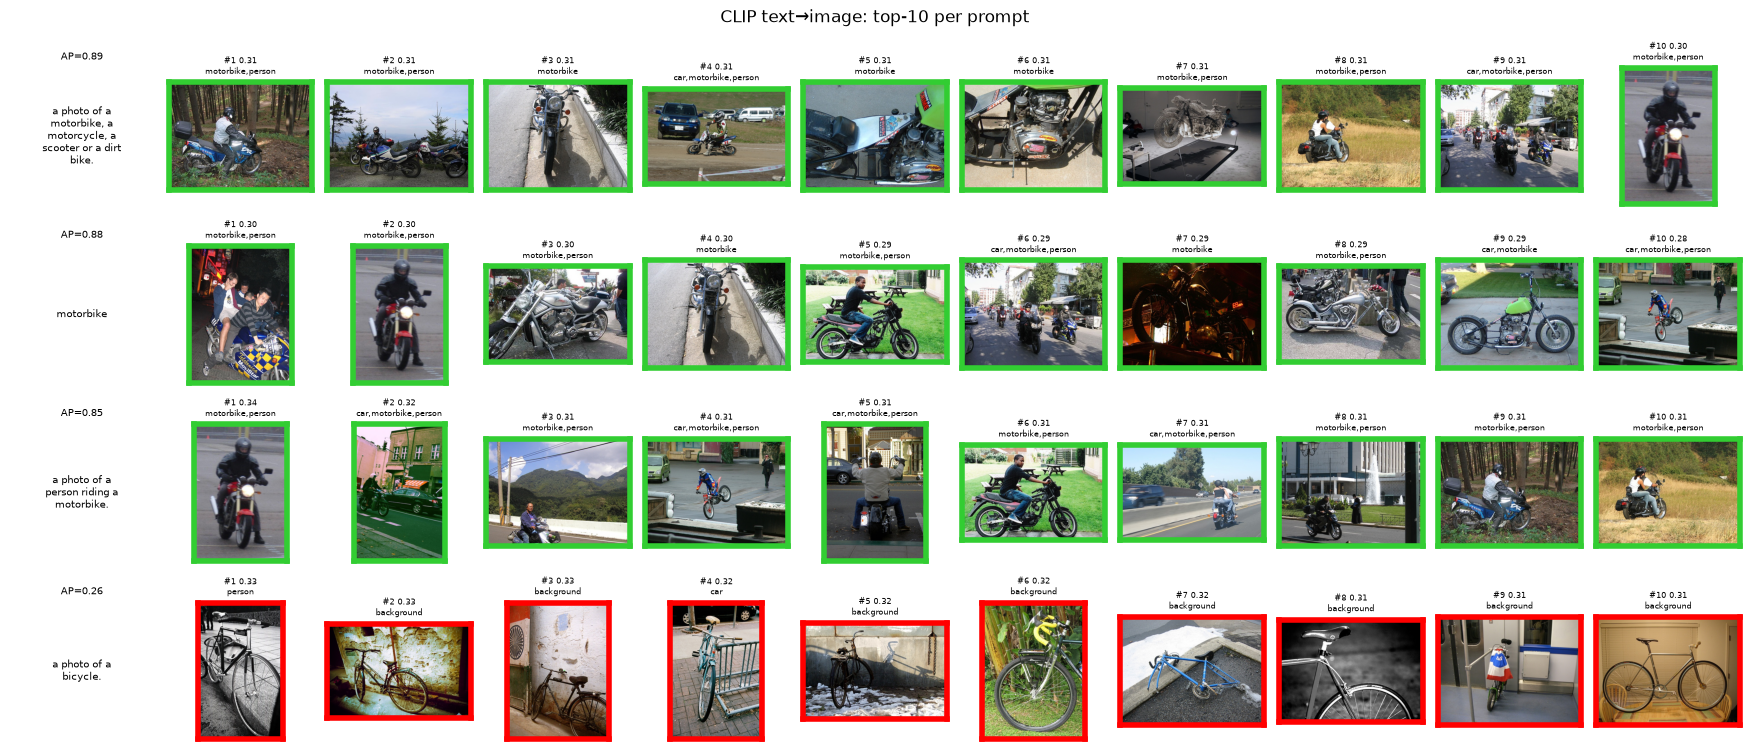

In [17]:
show = [best_prompt, "motorbike", "a photo of a person riding a motorbike.", "a photo of a bicycle."]
show = list(dict.fromkeys(show))
rows = [(f"AP={text_tab.loc[p, ('AP', 'test')]:.2f}", p, text_S["test"][R.TEXT_QUERIES.index(p)]) for p in show]
fig = R.show_results(rows, "test", title="CLIP text→image: top-10 per prompt")
save(fig, "stageC_examples_clip_text")

### C7. Most frequent false positives

Irrelevant images that appear most often in the top-20 over all queries. They
show what each representation confuses with a motorbike.

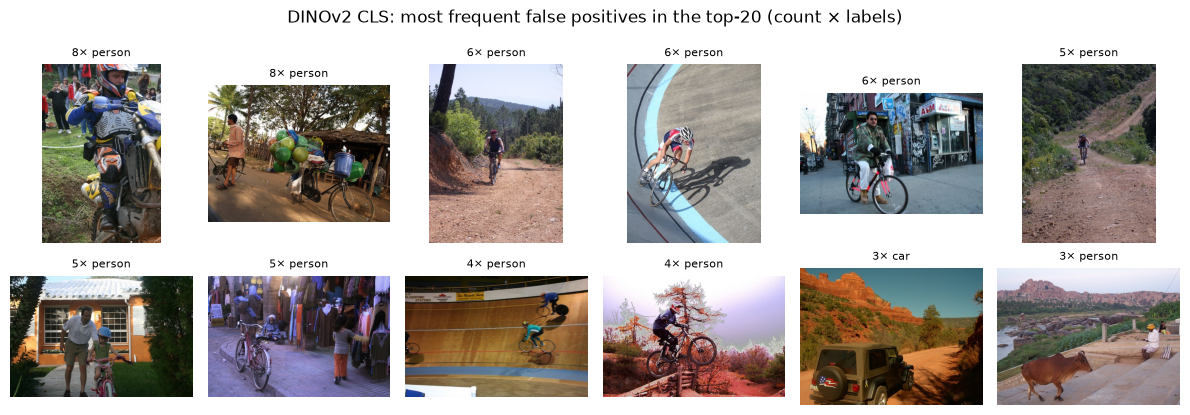

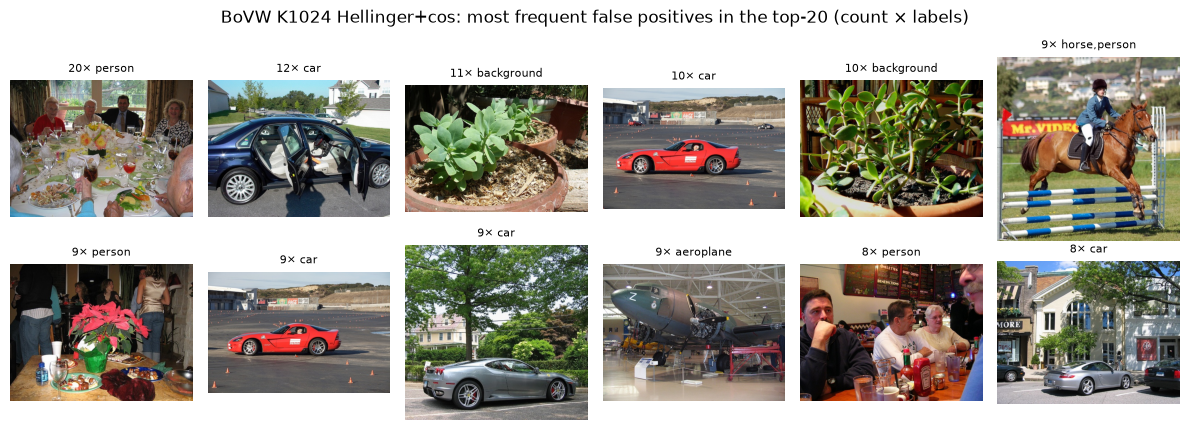

In [18]:
for fam in [f for f in ("DINOv2", "BoVW") if f in best.index]:
    fp = R.frequent_false_positives(test_S[best[fam]], "test")
    fig = R.show_queries([n for n, _, _ in fp], [f"{c}× {l}" for _, c, l in fp],
                         title=f"{best[fam]}: most frequent false positives in the top-20 (count × labels)")
    save(fig, f"stageC_false_positives_{fam}")

## Observations (test corpus, 96 queries unless stated)

1. **Best strategy.** Deep global embeddings win by a wide margin: DINOv2 CLS
   mAP 0.645 (P@10 0.84), ResNet-18 layer4 0.548, CLIP image 0.464. CLIP
   text→image with the val-chosen prompt reaches AP 0.888 (P@10 = 1.0), but
   that is a single query, not an average over 96 images. Handcrafted methods
   stay at mAP ≈ 0.10–0.11 (random ≈ 0.05; P@10 ≈ 0.2). Val and test give
   the same order of methods.
2. **Local vs global.** BoVW/VLAD/FV match local gradient patterns (wheels,
   textures, metal, road). The most frequent false positives (C7) are cars
   (wheels, bodywork) and cluttered, texture-rich scenes (dinner tables,
   plants) that act as "hubs" close to many queries. The deep embeddings encode the object as a whole and are
   robust to viewpoint and background.
3. **Vocabulary and PCA.** Hellinger BoVW goes 0.105 → 0.108 → 0.110 for
   K = 256 → 512 → 1024, a small gain at 4× the dimension. PCA on BoVW costs
   ~15 % (K1024: 0.110 → 0.093 for 128–1024 dims). At equal dimension (1024),
   the small codebook K=256 (0.105) beats K=1024 + PCA (0.093). For Fisher
   vectors PCA *helps* (0.072 → 0.105 with 256 dims): the 20k-D vector holds
   many noisy dimensions. For VLAD it is neutral (0.096 → 0.092).
4. **Normalisation.** Hellinger (√L1) and histogram intersection are the best
   BoVW options. Plain L2 is even worse than raw counts because a few very
   frequent visual words dominate the cosine. Power normalisation also helps
   VLAD and FV.
5. **Query diversity.** DINOv2 mAP is 0.841 with the *typical* set and 0.587
   with the *diverse* set. AP correlates with query typicality (Spearman ≈ 0.79
   for deep features). The worst query (008315) is a bus scene with a tiny
   motorbike. Averaging the 12 diverse queries into one query gives 0.938
   (DINOv2): combining examples helps a lot.
6. **CLIP wording.** Test AP goes from 0.751 to 0.888 across the 7 motorbike
   prompts. More detail does *not* help ("…parked on the street" 0.751,
   detailed close-up 0.765), while listing synonyms (motorcycle, scooter, dirt
   bike) does. The *bicycle* control falls to 0.256.
7. **Limitations.** Only 125 relevant test images (24 on val, so val choices
   are noisy). 88 of the 125 relevant images are multi-label, and some
   motorbikes are tiny or occluded. Labels mark presence, not salience. The
   diverse/typical sets are built with DINOv2, which may favour it, hence the
   all-query mAP is the main number. CLIP text has a single query per prompt
   (no std).